# Quantify curtailed volume and cost per year

Tidy Table


In [2]:
import pandas as pd

df = pd.read_parquet("../data/processed/scottish_wind_curtailment.parquet")
df["year"] = df["start_local"].dt.year

annual = (
    df.groupby("year")
      .agg(curtailed_gwh=("curtailed_mwh", lambda s: s.sum() / 1_000),
           payments_gbp_m=("payment_gbp", lambda s: s.sum() / 1_000_000),
           units_curtailed=("bmUnit", "nunique"))
)
annual["avg_price_gbp_per_mwh"] = (
    annual["payments_gbp_m"] * 1_000_000 / (annual["curtailed_gwh"] * 1_000)
)
annual.round(1)

,curtailed_gwh,payments_gbp_m,units_curtailed,avg_price_gbp_per_mwh
year,,,,
2024,1655.3,381.0,126,230.2
2025,1291.9,361.8,130,280.0
2026,849.2,284.2,135,334.7


In [3]:
df["month"] = df["start_local"].dt.to_period("M")
monthly = df.groupby("month")[["curtailed_mwh", "payment_gbp"]].sum()

C:\Users\cjlav\AppData\Local\Temp\ipykernel_14456\2092844202.py:1: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df["month"] = df["start_local"].dt.to_period("M")


In [4]:
df["hour"] = df["start_local"].dt.hour
hourly = df.groupby("hour")["curtailed_mwh"].sum()

In [5]:
by_unit = (df.groupby(["bmUnit", "bmUnitName"])
             [["curtailed_mwh", "payment_gbp"]].sum()
             .sort_values("payment_gbp", ascending=False))
by_unit["share_of_total"] = by_unit["payment_gbp"] / by_unit["payment_gbp"].sum()

In [7]:
import sys
from datetime import timedelta
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

sys.path.append("../src")          # so the notebook can import elexon.py
from elexon import get

FIG = Path("../figures")
FIG.mkdir(exist_ok=True)

df = pd.read_parquet("../data/processed/scottish_wind_curtailment.parquet")
df["year"] = df["start_local"].dt.year

ACCENT = "#1f6feb"   # the thing you want noticed
GREY = "#b0b7c3"     # everything else
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "axes.titlelocation": "left",
})

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / name, dpi=200, bbox_inches="tight")

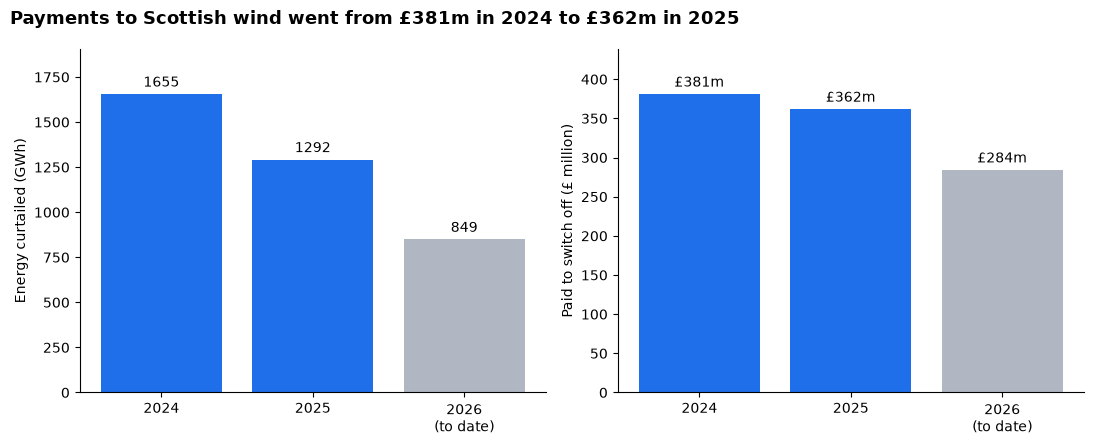

In [8]:
annual = df.groupby("year").agg(
    gwh=("curtailed_mwh", lambda s: s.sum() / 1_000),
    gbp_m=("payment_gbp", lambda s: s.sum() / 1_000_000),
)
this_year = pd.Timestamp.now().year
labels = [f"{y}\n(to date)" if y == this_year else str(y) for y in annual.index]
colors = [GREY if y == this_year else ACCENT for y in annual.index]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
panels = [("gwh", "Energy curtailed (GWh)", "%.0f"),
          ("gbp_m", "Paid to switch off (£ million)", "£%.0fm")]
for ax, (col, label, fmt) in zip(axes, panels):
    bars = ax.bar(labels, annual[col], color=colors)
    ax.bar_label(bars, fmt=fmt, padding=3)
    ax.set_ylabel(label)
    ax.set_ylim(0, annual[col].max() * 1.15)

full = annual[annual.index < this_year]
first, last = full.index.min(), full.index.max()
fig.suptitle(
    f"Payments to Scottish wind went from £{full.loc[first, 'gbp_m']:.0f}m "
    f"in {first} to £{full.loc[last, 'gbp_m']:.0f}m in {last}",
    x=0.01, ha="left", fontweight="bold", fontsize=13,
)
save(fig, "01_annual.png")

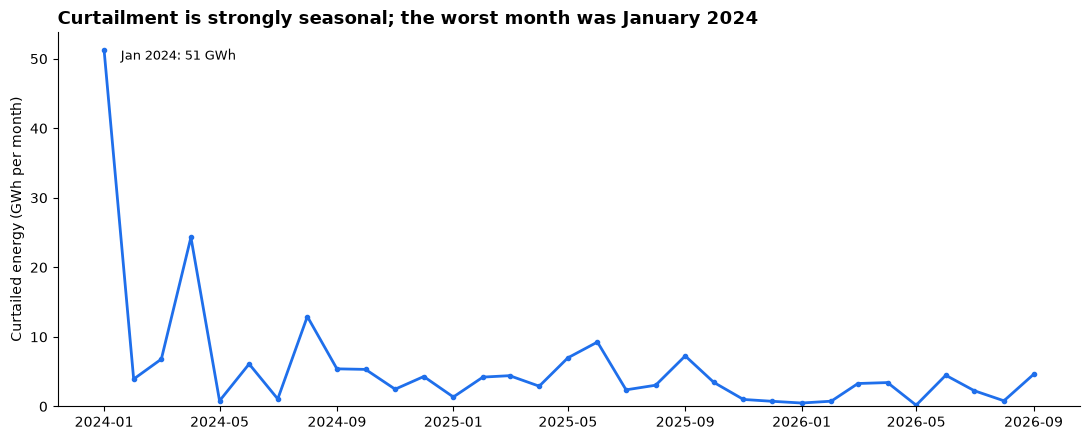

In [7]:
monthly = df.set_index("start_local")["curtailed_mwh"].resample("MS").sum() / 1_000
monthly.index = monthly.index.tz_localize(None)
monthly = monthly.iloc[:-1]            # drop the current, incomplete month

peak = monthly.idxmax()
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(monthly.index, monthly.values, color=ACCENT, linewidth=2, marker="o", markersize=3)
ax.annotate(f"{peak:%b %Y}: {monthly.max():,.0f} GWh",
            xy=(peak, monthly.max()), xytext=(12, -4),
            textcoords="offset points", va="center", fontsize=9)
ax.set_ylim(bottom=0)
ax.set_ylabel("Curtailed energy (GWh per month)")
ax.set_title(f"Curtailment is strongly seasonal; the worst month was {peak:%B %Y}")
save(fig, "02_monthly.png")

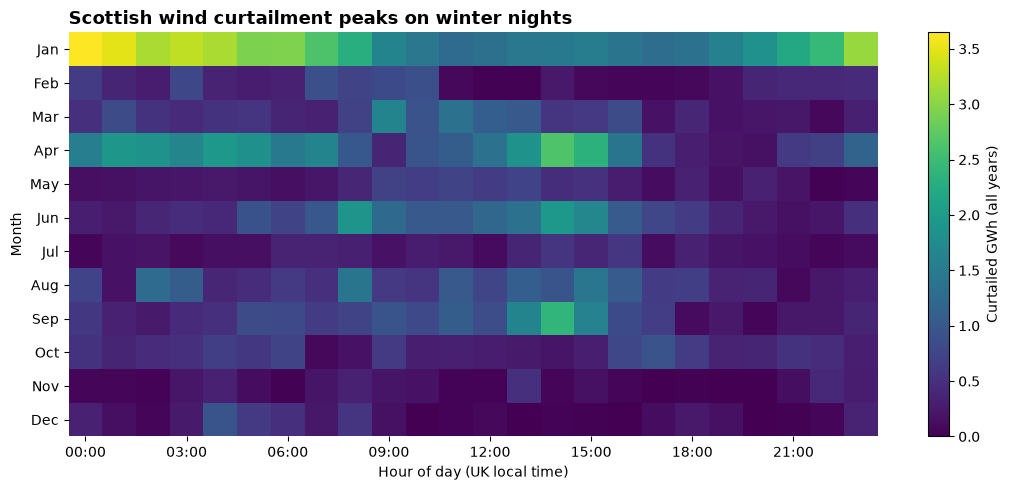

In [ ]:
df["month_num"] = df["start_local"].dt.month
df["hour"] = df["start_local"].dt.hour
heat = (df.pivot_table(index="month_num", columns="hour",
                       values="curtailed_mwh", aggfunc="sum")
          .reindex(index=range(1, 13), columns=range(24), fill_value=0) / 1_000)

fig, ax = plt.subplots(figsize=(11, 5))
im = ax.imshow(heat, aspect="auto", cmap="viridis")
ax.set_xticks(range(0, 24, 3), [f"{h:02d}:00" for h in range(0, 24, 3)])
ax.set_yticks(range(12), ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                          "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_xlabel("Hour of day (UK local time)")
ax.set_ylabel("Month")
ax.spines[:].set_visible(False)
fig.colorbar(im, ax=ax, label="Curtailed GWh (all years)")
ax.set_title("Scottish wind curtailment peaks on winter nights")  
save(fig, "03_heatmap_month_hour.png")

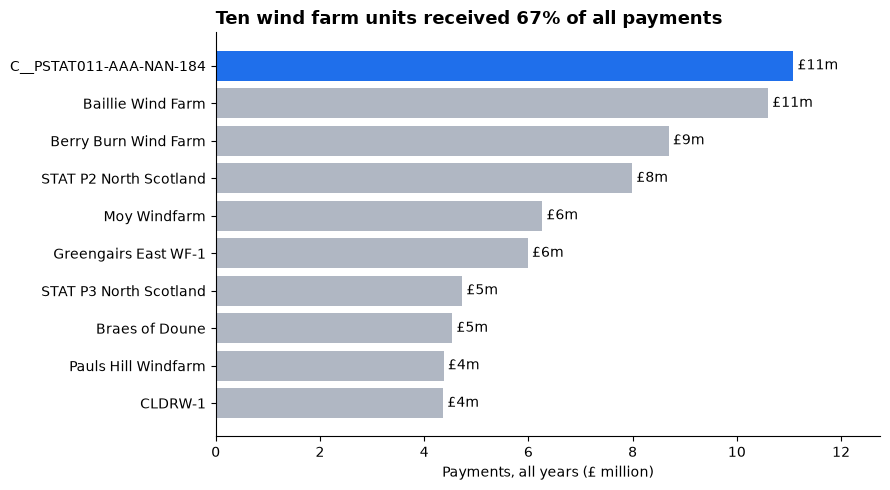

In [9]:
by_unit = (df.groupby("bmUnitName")["payment_gbp"].sum() / 1_000_000).sort_values(ascending=False)
top = by_unit.head(10).iloc[::-1]       # reversed so the largest bar sits at the top
share = by_unit.head(10).sum() / by_unit.sum()

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(top.index, top.values, color=[GREY] * (len(top) - 1) + [ACCENT])
ax.bar_label(bars, fmt="£%.0fm", padding=3)
ax.set_xlim(0, top.max() * 1.15)
ax.set_xlabel("Payments, all years (£ million)")
ax.set_title(f"Ten wind farm units received {share:.0%} of all payments")
save(fig, "04_top_farms.png")

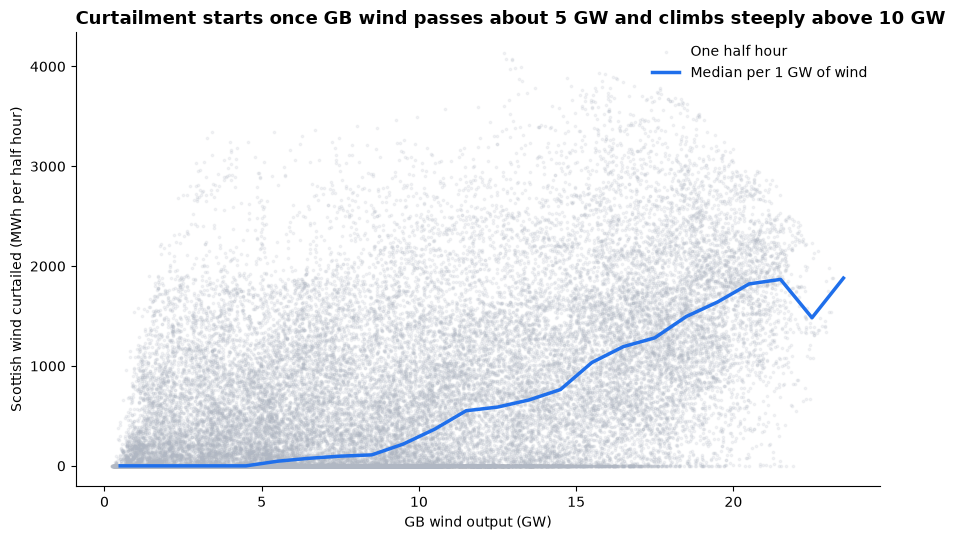

In [14]:
RAW_WIND = Path("../data/raw/wind_outturn")
RAW_WIND.mkdir(parents=True, exist_ok=True)

d = df["start_utc"].min().normalize().tz_localize(None)
end = df["start_utc"].max().normalize().tz_localize(None)
while d <= end:
    out = RAW_WIND / f"{d:%Y-%m-%d}.parquet"
    if not out.exists():
        rows = get("/generation/actual/per-type/wind-and-solar",
                   {"from": f"{d:%Y-%m-%d}", "to": f"{d + timedelta(days=6):%Y-%m-%d}"})
        pd.DataFrame(rows).to_parquet(out, index=False)
    d += timedelta(days=6)              # windows overlap slightly; duplicates removed below

wind = pd.concat([pd.read_parquet(f) for f in RAW_WIND.glob("*.parquet")], ignore_index=True)
wind = wind[wind["psrType"].isin(["Wind Onshore", "Wind Offshore"])]
wind = wind.sort_values("publishTime").drop_duplicates(["startTime", "psrType"], keep="last")
gb_wind = wind.groupby("startTime")["quantity"].sum() / 1_000          # MW to GW
gb_wind.index = pd.to_datetime(gb_wind.index, utc=True)

curt = df.groupby("start_utc")["curtailed_mwh"].sum()
both = gb_wind.rename("wind_gw").to_frame().join(curt).fillna({"curtailed_mwh": 0})

bins = pd.cut(both["wind_gw"], bins=range(0, int(both["wind_gw"].max()) + 2))
binned = both.groupby(bins, observed=True)["curtailed_mwh"].median()

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(both["wind_gw"], both["curtailed_mwh"], s=3, alpha=0.15,
           color=GREY, rasterized=True, label="One half hour")
ax.plot([b.mid for b in binned.index], binned.values, color=ACCENT,
        linewidth=2.5, label="Median per 1 GW of wind")
ax.set_xlabel("GB wind output (GW)")
ax.set_ylabel("Scottish wind curtailed (MWh per half hour)")
ax.legend(frameon=False)
ax.set_title("Curtailment starts once GB wind passes about 5 GW and climbs steeply above 10 GW")  
save(fig, "05_wind_vs_curtailment.png")

In [9]:
from pathlib import Path
import pandas as pd

RAW, PROC = Path("../data/raw"), Path("../data/processed")
units = pd.read_csv(PROC / "scottish_wind_units.csv")
allu = pd.read_csv(PROC / "bmunits_all.csv")

# rows with payment but no volume (or the reverse)?
print(df.groupby("_merge", observed=True)[["curtailed_mwh", "payment_gbp"]].sum())

# what dataType labels exist for Scottish units, and how much volume each holds (Jan 2025)
vol = pd.concat([pd.read_parquet(f) for f in sorted((RAW / "volumes").glob("2025-01-*.parquet"))])
v = vol[vol["bmUnit"].isin(units["elexonBmUnit"])]
print(v.groupby("dataType")["totalVolumeAccepted"].agg(["count", "sum"]))

        curtailed_mwh   payment_gbp
_merge                             
both     3.796387e+06  1.027009e+09
                 count            sum
dataType                             
Original         13275  -57225.568644
Original-Priced  13275  -13487.756589
Re-priced        13275  -15548.685803
Tagged           13275 -555313.822294


In [10]:
cash = pd.concat([pd.read_parquet(f) for f in sorted((RAW / "cashflows").glob("2025-01-*.parquet"))])
top = (cash.groupby("bmUnit")["totalCashflow"].sum()
           .sort_values(ascending=False).head(40).to_frame("paid_gbp"))
top = top.join(allu.set_index("elexonBmUnit")[["bmUnitName", "fuelType", "gspGroupId", "gspGroupName"]])
top["in_my_list"] = top.index.isin(units["elexonBmUnit"])
top

,paid_gbp,bmUnitName,fuelType,gspGroupId,gspGroupName,in_my_list
bmUnit,,,,,,
T_MOWEO-2,575893.102226,Moray East OWF2,WIND,NaN,NaN,True
T_MOWEO-3,569826.370611,Moray East OWF3,WIND,NaN,NaN,True
T_MOWEO-1,558367.483144,Moray East OWF1,WIND,NaN,NaN,True
T_KLGLW-1,378165.868813,Kilgallioch Windfarm,WIND,NaN,NaN,True
T_WISTW-2,343077.928547,Brockloch Rig 2 WF Exp A,WIND,NaN,NaN,True
T_CREAW-1,281020.436272,Creag Riabhach Wind Farm,WIND,NaN,NaN,True
T_MOWWO-3,263468.188244,Moray West OWF3,WIND,NaN,NaN,True
T_BHLAW-1,260263.401525,Bhlaraidh Windfarm 1,WIND,NaN,NaN,True
T_STRNW-1,220371.675204,Strathy North Wind Farm 1,WIND,NaN,NaN,True


In [11]:
import sys; sys.path.append("../src")
from elexon import get

day = "2025-01-15"
test = ["T_MOWEO-1", "T_SGRWO-1", "T_KLGLW-1", "E_BRYBW-1"]

boav = pd.DataFrame(get(f"/balancing/settlement/acceptance/volumes/all/bid/{day}"))
disp = pd.read_parquet(RAW / "volumes" / f"{day}.parquet")
cash_d = pd.read_parquet(RAW / "cashflows" / f"{day}.parquet")

comp = pd.DataFrame({"BOAV": boav[boav["bmUnit"].isin(test)].groupby("bmUnit")["totalVolumeAccepted"].sum()})
for dt in disp["dataType"].unique():
    sub = disp[(disp["bmUnit"].isin(test)) & (disp["dataType"] == dt)]
    comp[dt] = sub.groupby("bmUnit")["totalVolumeAccepted"].sum()
comp["cash_gbp"] = cash_d[cash_d["bmUnit"].isin(test)].groupby("bmUnit")["totalCashflow"].sum()
comp["gbp_per_mwh_BOAV"] = comp["cash_gbp"] / -comp["BOAV"]
comp.round(1)

,BOAV,Original,Original-Priced,Re-priced,Tagged,cash_gbp,gbp_per_mwh_BOAV
bmUnit,,,,,,,
T_MOWEO-1,-4538.9,-236.5,0.0,0.0,-4538.9,6122.2,1.3
T_SGRWO-1,-3893.9,0.0,0.0,-13.2,-3893.8,8120.6,2.1


In [12]:
import pandas as pd
df = pd.read_parquet("../data/processed/scottish_wind_curtailment.parquet")
df["year"] = df["start_local"].dt.year

annual = df.groupby("year").agg(curtailed_gwh=("curtailed_mwh", lambda s: s.sum() / 1e3),
                                payments_gbp_m=("payment_gbp", lambda s: s.sum() / 1e6),
                                units=("bmUnit", "nunique"))
annual["avg_gbp_per_mwh"] = annual["payments_gbp_m"] * 1e6 / (annual["curtailed_gwh"] * 1e3)
print(annual.round(1))

jan_sep = df[df["start_local"].dt.month <= 9].groupby("year")[["curtailed_mwh", "payment_gbp"]].sum()
print("\nJan–Sep like-for-like (GWh, £m):\n", (jan_sep / [1e3, 1e6]).round(1))

m = df.set_index("start_local")["curtailed_mwh"].resample("MS").sum() / 1e3
print("\nTop 5 months (GWh):\n", m.sort_values(ascending=False).head(5).round(0))

h = df.groupby(df["start_local"].dt.hour)["curtailed_mwh"].sum()
print("\nShare of curtailment by hour (%):\n", (100 * h / h.sum()).round(1).to_string())

u = df.groupby("bmUnitName")["payment_gbp"].sum().sort_values(ascending=False)
print("\nTop 10 units (£m):\n", (u.head(10) / 1e6).round(1))
print(f"Top-10 share of payments: {u.head(10).sum() / u.sum():.0%}")
print("\nPeriod:", df["start_local"].min(), "to", df["start_local"].max())

      curtailed_gwh  payments_gbp_m  units  avg_gbp_per_mwh
year                                                       
2024         8241.8           381.0    126             46.2
2025        10068.4           361.8    130             35.9
2026        10616.3           284.2    135             26.8

Jan–Sep like-for-like (GWh, £m):
       curtailed_mwh  payment_gbp
year                            
2024         5033.8        254.7
2025         6825.9        240.3
2026         8740.1        232.1

Top 5 months (GWh):
 start_local
2026-10-01 00:00:00+01:00    1876.0
2026-09-01 00:00:00+01:00    1816.0
2026-03-01 00:00:00+00:00    1471.0
2024-12-01 00:00:00+00:00    1358.0
2025-10-01 00:00:00+01:00    1282.0
Name: curtailed_mwh, dtype: float64

Share of curtailment by hour (%):
 start_local
0     4.5
1     4.4
2     4.4
3     4.3
4     4.3
5     4.4
6     4.3
7     4.1
8     3.9
9     3.7
10    3.7
11    3.7
12    3.7
13    3.8
14    4.0
15    4.1
16    4.2
17    4.2
18    4.3
19    4.4
20